# Statistical Analysis, Clustering and Country Prioritization

This notebook covers hypothesis testing, data preprocessing, unsupervised clustering, dimensionality reduction, model comparison, and country prioritization for HELP International's aid-allocation problem.

In [1]:
import pandas as pd
from scipy.stats import spearmanr,pearsonr,shapiro,kruskal, mannwhitneyu,yeojohnson
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("../data/raw/Country-data.csv")
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## 1. Income vs Child Mortality

**Research Question:** Is income significantly associated with child mortality across countries?

**Null Hypothesis (H₀):** There is no significant association between income and child mortality.

**Alternative Hypothesis (H₁):** There is a significant association between income and child mortality.

In [83]:
corr,p_value = spearmanr(df['income'],df['child_mort'])

print("Spearman Correlation:", corr)
print("P-value",p_value)

Spearman Correlation: -0.8667875995961556
P-value 9.863580790065488e-52


**Test Selection:**

Spearman rank correlation is used because income is strongly right-skewed, contains extreme values, and the relationship with child mortality is not best represented as a simple linear relationship on the raw income scale. Spearman correlation evaluates monotonic association using ranks and is less sensitive to extreme numerical values than Pearson correlation.

**Result and Interpretation:**

- Spearman correlation coefficient: approximately `-0.87`
- P-value: approximately `9.86 × 10⁻⁵²`
- Since the p-value is much smaller than the significance level of `0.05`, the null hypothesis is rejected.
- There is a statistically significant and strong negative association between income and child mortality.
- Countries with higher income generally tend to have lower child mortality.
- This result indicates association and should not be interpreted as evidence that higher income directly causes lower child mortality.

## 2. Income vs Life Expectancy

**Research Question:** Is income significantly associated with life expectancy across countries?

**Null Hypothesis (H₀):** There is no significant association between income and life expectancy.

**Alternative Hypothesis (H₁):** There is a significant association between income and life expectancy.

In [4]:
corr,p_value = spearmanr(df['income'],df['life_expec'])
print("Spearman Coeffecient:",corr)
print("P-value:",p_value)

Spearman Coeffecient: 0.8420117900163497
P-value: 4.3583317035727184e-46


**Result and Interpretation:**

- Spearman correlation coefficient: approximately `0.84`
- P-value: approximately `4.36 × 10⁻⁴⁶`
- Since the p-value is much smaller than the significance level of `0.05`, the null hypothesis is rejected.
- There is a statistically significant and strong positive association between income and life expectancy.
- Countries with higher income generally tend to have higher life expectancy.
- The result represents an association and should not be interpreted as evidence of causation.

## 3. Total Fertility vs Child Mortality

### 3.1 Spearman Rank Correlation — Monotonic Association

**Research Question:** Is total fertility significantly associated with child mortality across countries?

**Null Hypothesis (H₀):** There is no significant association between total fertility and child mortality.

**Alternative Hypothesis (H₁):** There is a significant association between total fertility and child mortality.

In [5]:
corr,p_value = spearmanr(df['total_fer'],df["child_mort"])
print("Spearman Coeffecient:",corr)
print("P-value:",p_value)

Spearman Coeffecient: 0.8697087876596
P-value: 1.7954896110884787e-52


### 3.2 Pearson Correlation — Linear Association

**Research Question:** Is total fertility significantly associated with child mortality across countries?

**Null Hypothesis (H₀):** There is no significant linear association between total fertility and child mortality.

**Alternative Hypothesis (H₁):** There is a significant linear association between total fertility and child mortality.

In [84]:
pearson_corr,p_value= pearsonr(df['total_fer'],df['child_mort'])
print("Pearson Coeffecient:",pearson_corr)
print("P-value:",p_value)

Pearson Coeffecient: 0.8484781105566706
P-value: 1.8377768900584315e-47


### 3.3 Comparison and Conclusion

**Result and Interpretation:**

- Pearson correlation coefficient: approximately `0.85`
- Pearson p-value: approximately `1.84 × 10⁻⁴⁷`
- Spearman correlation coefficient: approximately `0.87`
- Spearman p-value: approximately `1.80 × 10⁻⁵²`
- Both methods indicate a strong positive and statistically significant association between total fertility and child mortality.
- Since both p-values are much smaller than the significance level of `0.05`, the null hypothesis is rejected.
- The slightly higher Spearman coefficient suggests that the monotonic relationship is marginally stronger than the purely linear relationship.
- The similarity of the two coefficients indicates that the conclusion is robust to the choice of correlation method.
- This association should not be interpreted as evidence of causation.

## 4. Life Expectancy Across Income Groups

**Research Question:** Does life expectancy differ significantly across low-, middle-, and high-income country groups?

**Null Hypothesis ($H_0$):** Life expectancy does not differ significantly across the Low-, Middle-, and High-income groups.

**Alternative Hypothesis ($H_1$):** Life expectancy differs significantly for at least one income group.

In [7]:
df.columns.tolist()

['country',
 'child_mort',
 'exports',
 'health',
 'imports',
 'income',
 'inflation',
 'life_expec',
 'total_fer',
 'gdpp']

In [8]:
df["income_group"] = pd.cut(df["income"],bins=[-np.inf,5000,20000,np.inf],labels=['Low','Middle','High'],right=False)

In [9]:
df["income_group"].value_counts(sort=False)

income_group
Low       52
Middle    65
High      50
Name: count, dtype: int64

### 4.1 Checking ANOVA Assumptions

**1. Independence of observations**

Each row represents a separate country, with one observation per country. Therefore, the observations are treated as independent for this analysis.

#### 4.1.2 Normality Check

One-way ANOVA assumes that the outcome variable is approximately normally distributed within each group. Therefore, the distribution of `life_expec` is evaluated separately for the Low-, Middle-, and High-income groups.

The group-wise histograms are first inspected visually, followed by the Shapiro-Wilk test for a formal assessment of normality.

For the Shapiro-Wilk test:

- **Null Hypothesis ($H_0$):** The data follows a normal distribution.
- **Alternative Hypothesis ($H_1$):** The data does not follow a normal distribution.
- **Significance level ($\alpha$):** `0.05`

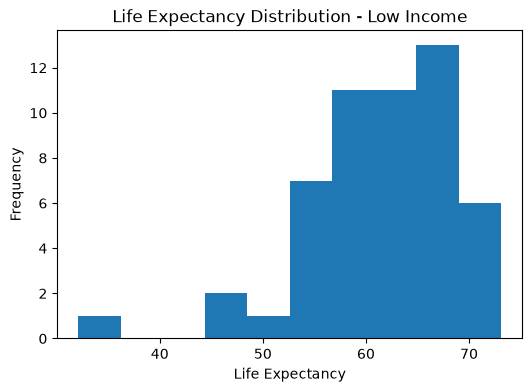

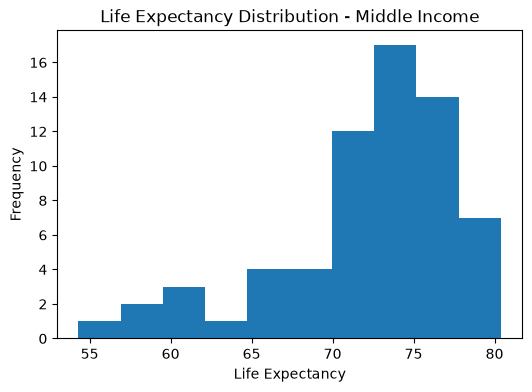

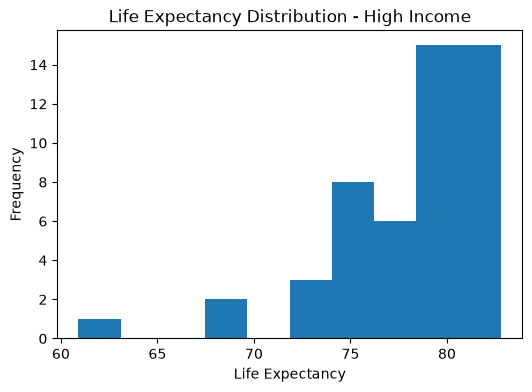

In [10]:
groups= ['Low','Middle','High']

for group in groups:
    data = df[df["income_group"]== group]["life_expec"]

    plt.figure(figsize=(6,4))
    plt.hist(data,bins=10)
    plt.title(f'Life Expectancy Distribution - {group} Income')
    plt.xlabel("Life Expectancy")
    plt.ylabel("Frequency")
    plt.show()
    


In [11]:
for group in groups:
    data = df[df['income_group']== group]['life_expec']

    stat,p_value = shapiro(data)

    print(group)
    print("Shapiro Statistic",stat)
    print("P-value",p_value)
    print()


Low
Shapiro Statistic 0.9134878788090914
P-value 0.001085513935374297

Middle
Shapiro Statistic 0.8833864276409478
P-value 1.750256382695542e-05

High
Shapiro Statistic 0.823793475827275
P-value 3.24414068467057e-06



**Normality Test Result:**

- The Shapiro-Wilk p-values for the Low, Middle, and High income groups are all below `0.05`.
- Therefore, the null hypothesis of normality is rejected for all three groups.
- Life expectancy is not normally distributed within any of the three income groups.
- This finding is also consistent with the skewness observed in the group-wise histograms.

### 4.2 Test Selection: Kruskal-Wallis Test

The Shapiro-Wilk test indicates that life expectancy is not normally distributed within any of the three income groups. The group-wise histograms also show skewness and extreme observations.

Because the normality assumption required for one-way ANOVA is not reasonably satisfied, the Kruskal-Wallis test is selected as a non-parametric alternative for comparing life expectancy across the three independent income groups.

**Null Hypothesis ($H_0$):** The distribution of life expectancy is the same across the Low-, Middle-, and High-income groups.

**Alternative Hypothesis ($H_1$):** At least one income group has a different life expectancy distribution.

In [12]:
low = df[df['income_group'] == 'Low']['life_expec']
middle = df[df['income_group'] == 'Middle']['life_expec']
high = df[df['income_group'] == 'High']['life_expec']

h_stat, p_value = kruskal(low, middle, high)

print("Kruskal-Wallis H-statistic:", h_stat)
print("P-value:", p_value)

Kruskal-Wallis H-statistic: 104.2218228334376
P-value: 2.3362468282077892e-23


### 4.3 Post-hoc Pairwise Comparison

The Kruskal-Wallis test confirms that a statistically significant difference in life expectancy exists among the income groups, but it does not identify which specific groups differ.

Pairwise Mann-Whitney U tests are therefore performed for:

- Low vs Middle
- Low vs High
- Middle vs High

Because three pairwise comparisons are performed, a Bonferroni correction is applied to control the overall Type I error rate.

**Adjusted significance level:**

$\alpha = 0.05 / 3 \approx 0.0167$

In [13]:
pairs = [
    ('Low', 'Middle'),
    ('Low', 'High'),
    ('Middle', 'High')
]

for group1, group2 in pairs:
    data1 = df[df['income_group'] == group1]['life_expec']
    data2 = df[df['income_group'] == group2]['life_expec']

    u_stat, p_value = mannwhitneyu(
        data1,
        data2,
        alternative='two-sided'
    )

    print(f"{group1} vs {group2}")
    print("U-statistic:", u_stat)
    print("P-value:", p_value)
    print()

Low vs Middle
U-statistic: 342.5
P-value: 1.480749389299269e-13

Low vs High
U-statistic: 42.0
P-value: 3.8263123751262223e-17

Middle vs High
U-statistic: 514.0
P-value: 3.709859451833857e-10



In [14]:
df.groupby('income_group', observed=True)['life_expec'].median()

income_group
Low       61.75
Middle    73.70
High      79.85
Name: life_expec, dtype: float64

### 4.4 Final Conclusion

- The Kruskal-Wallis test found a statistically significant difference in life-expectancy distributions across the Low-, Middle-, and High-income groups (`p < 0.05`).
- Post-hoc Mann-Whitney U tests were performed for all three pairwise comparisons using a Bonferroni-adjusted significance level of approximately `0.0167`.
- All three comparisons — Low vs Middle, Low vs High, and Middle vs High — remained statistically significant after the correction.
- Median life expectancy increases consistently across the income groups:
  - Low income: `61.75` years
  - Middle income: `73.70` years
  - High income: `79.85` years
- Therefore, higher-income groups tend to exhibit higher typical life expectancy in this dataset.
- These results establish association between income grouping and life expectancy differences, but they do not establish that income alone causes the differences in life expectancy.

## 5. Preprocessing Strategy

### 5.1 Transformation Decisions

In [15]:
data= ["child_mort","exports","imports","income","gdpp"]

for col in data:

    result = np.log1p(df[col])
    print(col)
    print("Original skewness:", df[col].skew())
    print("After log transformation", result.skew())
    print()




child_mort
Original skewness: 1.4507735387555047
After log transformation 0.06615993685980348

exports
Original skewness: 2.4458240051613496
After log transformation -1.0889611543161872

imports
Original skewness: 1.90527571988626
After log transformation -1.8227941254683322

income
Original skewness: 2.231479607767527
After log transformation -0.23582308003947594

gdpp
Original skewness: 2.2180514519497163
After log transformation 0.006548003622863535



In [16]:
data= ["exports","imports"]

for col in data:

    print(col)
    print("Original skewness:", df[col].skew())
    print("After sq.root log transformation", np.sqrt(df[col]).skew())
    print()
    

exports
Original skewness: 2.4458240051613496
After sq.root log transformation 0.7423020393750691

imports
Original skewness: 1.90527571988626
After sq.root log transformation 0.47512556356740426



In [17]:
inflation_yj, lambda_value = yeojohnson(df['inflation'])

print("Original skewness:", df['inflation'].skew())
print("After Yeo-Johnson:", pd.Series(inflation_yj).skew())
print("Lambda:", lambda_value)

Original skewness: 5.154049359697971
After Yeo-Johnson: 0.18250597968152152
Lambda: 0.4278346215723399


#### Transformation Strategy

EDA revealed substantial skewness in several numerical features. Since clustering algorithms such as K-Means rely on distance calculations, highly skewed distributions and extreme values can disproportionately influence cluster formation.

Rather than removing genuine extreme countries, transformations were evaluated to reduce skewness while preserving the observations.

- `child_mort`, `income`, and `gdpp`: log1p transformation substantially reduced right skewness.
- `exports` and `imports`: square-root transformation was preferred because log transformation over-corrected the distributions.
- `inflation`: Yeo-Johnson transformation was selected because the feature contains negative values and therefore cannot be directly log- or square-root-transformed.
- `health`, `life_expec`, and `total_fer` were retained without transformation because their skewness was not considered severe enough to justify additional transformation.

The transformations will later be incorporated into a reproducible preprocessing pipeline before scaling and clustering.

### 5.2 Outlier Handling Strategy

EDA identified several genuine extreme observations across socioeconomic and health indicators. These observations are retained because they may represent meaningful country conditions rather than data-quality errors.

Since K-Means is distance-based, the influence of extreme values is addressed through appropriate feature transformations and scaling rather than removing or winsorizing the observations.

### 5.3 Applying Selected Transformations

Based on the skewness analysis, the selected transformations are now applied to a copy of the original dataframe. The original dataframe is preserved for interpretation and comparison, while `df_model` will be used for subsequent preprocessing and clustering.

In [18]:
df_model = df.copy()

In [19]:
df_model['child_mort'] = np.log1p(df_model['child_mort'])
df_model['income'] = np.log1p(df_model['income'])
df_model['gdpp'] = np.log1p(df_model['gdpp'])

df_model['exports'] = np.sqrt(df_model['exports'])
df_model['imports'] = np.sqrt(df_model['imports'])
df_model['inflation'], lambda_value = yeojohnson(df_model['inflation'])

### 5.4 Correlated Feature Review

Highly correlated features may overweight the same underlying information in distance-based clustering. Therefore, correlations are re-evaluated after transformation before finalizing the clustering feature set.

In [20]:
p_corr = df_model[["income","gdpp"]].corr()

p_corr

,income,gdpp
income,1.000000,0.972024
gdpp,0.972024,1.000000


In [21]:
df_model[['income', 'gdpp', 'child_mort', 'life_expec']].corr()

,income,gdpp,child_mort,life_expec
income,1.000000,0.972024,-0.859310,0.805912
gdpp,0.972024,1.000000,-0.874668,0.797811
child_mort,-0.859310,-0.874668,1.000000,-0.883332
life_expec,0.805912,0.797811,-0.883332,1.000000


`income` and `gdpp` showed very high correlation after transformation
(Pearson r ≈ 0.97), indicating substantial redundancy. Their relationships
with key development indicators such as child mortality and life expectancy
were also very similar.

To avoid overweighting the economic-capacity dimension in distance-based
clustering, `income` was excluded and `gdpp` was retained as the primary
economic-capacity indicator.

### 5.5 Scaling Strategy

The clustering algorithms considered in this project are sensitive to differences in feature scale because their cluster formation relies on distance calculations.

Without scaling, variables with larger numerical ranges may disproportionately influence the clustering structure.

The strongly skewed variables were first transformed to reduce extreme numerical spread. Since these transformations substantially reduced skewness, StandardScaler is selected as the primary scaling method.

The same standardized feature matrix will initially be used for K-Means, Hierarchical Clustering, and DBSCAN to allow a fair comparison between clustering approaches.

In [22]:
clustering_features = ['child_mort','exports','health','imports','inflation','life_expec','total_fer','gdpp']

### 5.6 Final Preprocessing Strategy

The preprocessing strategy for clustering is:

- Retain genuine extreme country observations rather than removing or winsorizing them.
- Apply selected transformations to strongly skewed features.
- Exclude `income` because of its very high redundancy with transformed `gdpp`.
- Retain `gdpp` as the primary economic-capacity feature.
- Exclude `country` from the numerical clustering matrix while preserving it for cluster interpretation and country-level recommendations.
- Standardize the final numerical features using StandardScaler before distance-based clustering.

## 6. Preparing Data for Clustering

The preprocessing decisions identified in the previous section are now applied to prepare the final numerical feature matrix for clustering.

### 6.1 Final Clustering Feature Matrix

The final clustering matrix contains eight numerical features. `country` is excluded because it is an identifier and does not represent a numerical characteristic for distance calculation. `income` is excluded because of its high redundancy with transformed `gdpp`.

In [23]:
X = df_model[clustering_features]

In [24]:
X.head()

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
0,4.513055,3.162278,7.58,6.700746,4.038811,56.2,5.82,6.317165
1,2.867899,5.291503,6.55,6.971370,2.505919,76.3,1.65,8.316545
2,3.342862,6.196773,4.17,5.603570,5.537502,76.5,2.89,8.403128
3,4.787492,7.893035,2.85,6.549809,6.668443,60.1,6.16,8.169336
4,2.424803,6.745369,6.03,7.674634,1.086089,76.8,2.13,9.409273


In [25]:
X.shape

(167, 8)

### 6.2 Feature Standardization

The selected features are standardized using `StandardScaler` so that differences in numerical scale do not disproportionately influence distance-based clustering.

`StandardScaler` learns the mean and standard deviation of each feature and transforms the values to approximately zero mean and unit standard deviation.

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [27]:
X_scaled.shape


(167, 8)

In [28]:
X_scaled[:5]

array([[ 1.27801205, -1.52915388,  0.27908825,  0.03554632,  0.45941569,
        -1.61909203,  1.90288227, -1.46030093],
       [-0.23970754, -0.4261476 , -0.09701618,  0.1978225 , -0.15465939,
         0.64786643, -0.85997281, -0.12283509],
       [ 0.19846398,  0.04281144, -0.96607302, -0.62236154,  1.05978954,
         0.67042323, -0.0384044 , -0.06491589],
       [ 1.53119057,  0.9215289 , -1.44807093, -0.05496121,  1.51284307,
        -1.17923442,  2.12815103, -0.22130867],
       [-0.64848077,  0.32700133, -0.28689415,  0.6195257 , -0.72344152,
         0.70425843, -0.54194633,  0.608135  ]])

In [29]:
X_scaled_df = pd.DataFrame(X_scaled,columns=clustering_features,index=X.index)
X_scaled_df.head()

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
0,1.278012,-1.529154,0.279088,0.035546,0.459416,-1.619092,1.902882,-1.460301
1,-0.239708,-0.426148,-0.097016,0.197823,-0.154659,0.647866,-0.859973,-0.122835
2,0.198464,0.042811,-0.966073,-0.622362,1.059790,0.670423,-0.038404,-0.064916
3,1.531191,0.921529,-1.448071,-0.054961,1.512843,-1.179234,2.128151,-0.221309
4,-0.648481,0.327001,-0.286894,0.619526,-0.723442,0.704258,-0.541946,0.608135


### 6.3 Validation of Scaled Features

The standardized feature matrix is validated to confirm that each feature has approximately zero mean and unit standard deviation.

StandardScaler centers each feature by subtracting its mean, resulting in a mean of approximately zero, and divides by its standard deviation, resulting in unit standard deviation. Therefore, the scaled values represent how many standard deviations an observation lies above or below the feature mean.

In [30]:
print("Mean:")
print(X_scaled_df.mean().round(3))

print("\nStandard deviation:")
print(X_scaled_df.std(ddof=0).round(3))

Mean:
child_mort   -0.0
exports       0.0
health        0.0
imports      -0.0
inflation     0.0
life_expec    0.0
total_fer     0.0
gdpp         -0.0
dtype: float64

Standard deviation:
child_mort    1.0
exports       1.0
health        1.0
imports       1.0
inflation     1.0
life_expec    1.0
total_fer     1.0
gdpp          1.0
dtype: float64


**Observation:**  

All eight standardized features have means approximately equal to `0` and standard deviations equal to `1`. This confirms that the scaling step was applied successfully and the final feature matrix is ready for clustering.

## 7. K-Means Clustering



### 7.1 K-Means Approach

K-Means is used to group countries with similar socioeconomic and health characteristics without predefined target labels.

The algorithm assigns observations to the nearest cluster centroid and iteratively updates the centroids until convergence. Since K-Means is distance-based, the standardized feature matrix prepared earlier is used.

K-Means++ initialization is used to reduce sensitivity to poor initial centroid selection.

### 7.2 Initial K-Means Model

An initial K-Means model is fitted using a trial value of `K = 3` to understand the model output and clustering workflow. This is not the final number of clusters; the optimal value of `K` will be evaluated subsequently.

In [31]:
kmeans_trial =KMeans(n_clusters=3,init='k-means++',n_init=10,random_state=42)

kmeans_trial.fit(X_scaled_df);

In [32]:
pd.Series(kmeans_trial.labels_).value_counts()

0    67
1    51
2    49
Name: count, dtype: int64

In [33]:
kmeans_trial.inertia_

701.2043886946831

### 7.3 Choosing the Number of Clusters

The trial model used `K = 3` only to understand the K-Means workflow. Since the appropriate number of clusters is not known in advance, multiple values of `K` are evaluated using the Elbow Method and Silhouette Score.

#### 7.3.1 Elbow Method

The Elbow Method compares the inertia (WCSS) obtained for different values of `K`. Inertia decreases as the number of clusters increases, so the aim is to identify the point after which adding more clusters produces only a relatively small improvement.

In [34]:
inertia_values = []
k_values = range(2,11)
for k in k_values:
    kmeans_model =KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    kmeans_model.fit(X_scaled_df)
    inertia_values.append(kmeans_model.inertia_)


for k,inertia in zip(k_values, inertia_values):
    print(f"K= {k} | Inertia = {inertia:.2f}")


K= 2 | Inertia = 853.05
K= 3 | Inertia = 701.20
K= 4 | Inertia = 615.33
K= 5 | Inertia = 549.37
K= 6 | Inertia = 507.08
K= 7 | Inertia = 471.00
K= 8 | Inertia = 444.46
K= 9 | Inertia = 400.61
K= 10 | Inertia = 385.79


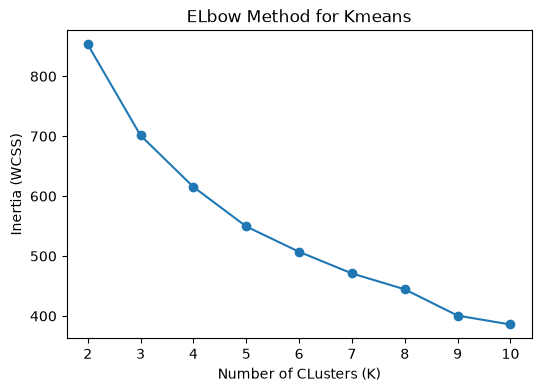

In [35]:
x = k_values
y = inertia_values
plt.figure(figsize=(6,4))
plt.plot(x,y, marker = 'o')
plt.xlabel("Number of CLusters (K)")
plt.ylabel("Inertia (WCSS)") 
plt.title("ELbow Method for Kmeans")
plt.show()


**Observation:**  
Inertia decreases consistently as the number of clusters increases. However, the elbow is not sharply defined. The rate of improvement appears to become more gradual around `K = 4–5`, so these values are treated as candidate cluster counts rather than selecting a final `K` based on the Elbow Method alone.

Silhouette analysis is therefore used as an additional criterion for selecting the number of clusters.

#### 7.3.2 Silhouette Analysis

Since the Elbow Method does not show a sharply defined optimal number of clusters, Silhouette Score is used as an additional evaluation metric.

The Silhouette Score measures both:
- how close observations are to other observations within their own cluster, and
- how separated they are from the nearest neighbouring cluster.

Scores range approximately from `-1` to `1`:
- closer to `1` → well-separated and compact clusters
- around `0` → overlapping/boundary observations
- below `0` → observations may be assigned to an inappropriate cluster

In [36]:
silhouette_scores = []

for k in k_values:
    kmeans_model = KMeans(n_clusters=k,init="k-means++",n_init=10,random_state=42)

    kmeans_model.fit(X_scaled_df)

    score = silhouette_score(X_scaled_df,kmeans_model.labels_)

    silhouette_scores.append(score)


for k,score in zip(k_values,silhouette_scores):
    print(f"K= {k} | Silhouette Score = {score:.3f}" )

K= 2 | Silhouette Score = 0.319
K= 3 | Silhouette Score = 0.239
K= 4 | Silhouette Score = 0.237
K= 5 | Silhouette Score = 0.238
K= 6 | Silhouette Score = 0.217
K= 7 | Silhouette Score = 0.215
K= 8 | Silhouette Score = 0.209
K= 9 | Silhouette Score = 0.224
K= 10 | Silhouette Score = 0.216


**Observation:**  
The highest Silhouette Score is obtained for `K = 2` (`0.319`), indicating that a two-cluster solution provides the strongest separation and cohesion among the tested values.

Scores for `K = 3` to `K = 5` are considerably lower and very similar to one another. Since the Elbow Method did not show a sharply defined elbow and suggested a broader candidate region around `K = 4–5`, the final number of clusters should not be selected from either metric alone. Candidate solutions will also be assessed based on cluster structure and business interpretability.

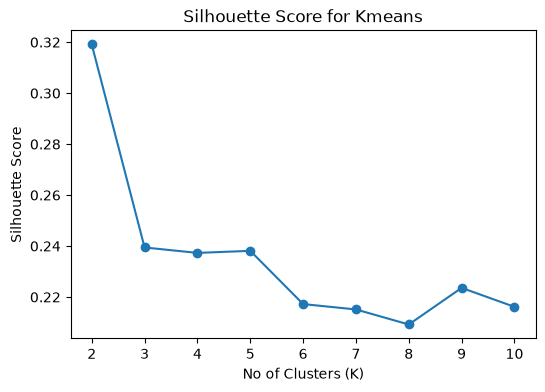

In [37]:
x= k_values
y = silhouette_scores
plt.figure(figsize=(6,4))
plt.plot(x,y,marker="o")
plt.xlabel("No of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Kmeans")
plt.show()

**Observation:**  
The Silhouette Score is highest for `K = 2` (approximately `0.319`), indicating the strongest combination of within-cluster cohesion and between-cluster separation among the tested solutions.

Scores for `K = 3`, `K = 4`, and `K = 5` are considerably lower and very similar. Since the Elbow Method did not reveal a sharply defined elbow, `K = 2` currently has the strongest quantitative support.

Before finalizing the number of clusters, candidate solutions are further examined for cluster composition and business interpretability.

#### 7.3.3 Candidate Cluster Comparison and Final K Selection

Since the Elbow Method did not indicate a clear optimal value of K and the Silhouette Score favored a broad two-cluster solution, candidate solutions with **K = 2, 3, and 4** were compared further.

The comparison considered:
- cluster sizes,
- country vulnerability profiles in original business units, and
- usefulness of the resulting segmentation for aid prioritization.

In [38]:
candidate_k = [2,3,4]

for k in candidate_k:
    kmeans_model = KMeans(n_clusters=k,init="k-means++",n_init=10,random_state=42)
    kmeans_model.fit(X_scaled_df)
    print(f"K = {k}")
    print(pd.Series(kmeans_model.labels_).value_counts().sort_index())
    print()




K = 2
0    99
1    68
Name: count, dtype: int64

K = 3
0    67
1    51
2    49
Name: count, dtype: int64

K = 4
0    50
1    19
2    64
3    34
Name: count, dtype: int64



In [39]:
kmeans_2 = KMeans( n_clusters=2,init='k-means++', n_init=10,random_state=42)

kmeans_2.fit(X_scaled_df);

In [40]:
df_k2 = df.copy()
df_k2['cluster'] = kmeans_2.labels_

In [41]:
df_k2.groupby('cluster')[clustering_features].median().round(2)

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,10.3,40.10,7.04,46.2,3.53,76.4,1.88,11900.0
1,65.6,24.95,5.34,41.5,8.21,62.0,4.58,1155.0


In [42]:
kmeans_3 = KMeans( n_clusters=3,init='k-means++', n_init=10,random_state=42)

kmeans_3.fit(X_scaled_df)

df_k3 = df.copy()
df_k3['cluster'] = kmeans_3.labels_

df_k3.groupby('cluster')[clustering_features].median().round(2)



,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,19.1,38.4,5.20,42.1,7.44,73.4,2.34,4540.0
1,88.2,23.5,5.69,42.7,8.79,60.4,5.02,897.0
2,4.6,45.5,9.11,47.9,1.16,80.0,1.63,28000.0


In [43]:
kmeans_4 = KMeans( n_clusters=4,init='k-means++', n_init=10,random_state=42)

kmeans_4.fit(X_scaled_df)

df_k4 = df.copy()
df_k4['cluster'] = kmeans_4.labels_

df_k4.groupby('cluster')[clustering_features].median().round(2)


,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,88.75,23.15,5.68,41.50,8.22,60.45,5.04,833.0
1,6.00,76.40,7.33,71.00,1.88,77.80,1.63,19800.0
2,19.25,40.50,5.22,44.90,7.32,72.95,2.40,4450.0
3,5.00,34.10,9.51,36.05,1.31,80.10,1.79,30650.0


**Final K Selection**

Although **K = 2** achieved the highest Silhouette Score (0.319), it produced only a broad vulnerable vs. less-vulnerable segmentation.

**K = 3** produced three clearly interpretable groups representing high, intermediate, and relatively low vulnerability. **K = 4** added further segmentation but did not meaningfully narrow the highest-vulnerability group and had a similar Silhouette Score to K = 3.

Considering both clustering quality and business interpretability, **K = 3 was selected as the final K-Means solution**.

### 7.4 Final K-Means Model and Cluster Interpretation

The final K-Means solution uses **K = 3**.

The three clusters represent distinct levels of country vulnerability:

- **Cluster 1 – High Vulnerability:** Higher child mortality and fertility, lower life expectancy, and lower GDPP. This cluster contains **51 countries** and represents the primary aid-priority group.
- **Cluster 0 – Intermediate Vulnerability:** Countries with moderate socioeconomic and health indicators.
- **Cluster 2 – Lower Vulnerability:** Countries with comparatively low child mortality, higher life expectancy, and stronger economic indicators.

The high-vulnerability cluster will be compared with the results from Hierarchical Clustering and DBSCAN before making the final aid-allocation recommendation.

In [44]:
kmeans_final = kmeans_3
df_final = df.copy()
df_final['cluster'] = kmeans_final.labels_

In [45]:
df_final.sample(10)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,income_group,cluster
61,Grenada,14.6,23.8,5.86,49.2,11200,0.480,71.3,2.24,7370,Middle,0
156,Ukraine,11.7,47.1,7.72,51.1,7820,13.400,70.4,1.44,2970,Middle,0
38,"Congo, Rep.",63.9,85.1,2.46,54.7,5190,20.700,60.4,4.95,2740,Middle,1
29,Canada,5.6,29.1,11.30,31.0,40700,2.870,81.3,1.63,47400,High,2
58,Germany,4.2,42.3,11.60,37.1,40400,0.758,80.1,1.39,41800,High,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530,Middle,1
116,Pakistan,92.1,13.5,2.20,19.4,4280,10.900,65.3,3.85,1040,Low,1
123,Qatar,9.0,62.3,1.81,23.8,125000,6.980,79.5,2.07,70300,High,0
92,"Macedonia, FYR",10.4,39.8,7.09,58.1,11400,2.040,74.0,1.47,4540,Middle,0
165,Yemen,56.3,30.0,5.18,34.4,4480,23.600,67.5,4.67,1310,Low,1


In [46]:
high_vulnerability = df_final[df_final['cluster'] == 1]

high_vulnerability[['country', 'child_mort', 'life_expec', 'total_fer', 'gdpp', 'inflation']]

,country,child_mort,life_expec,total_fer,gdpp,inflation
0,Afghanistan,90.2,56.2,5.82,553,9.440
3,Angola,119.0,60.1,6.16,3530,22.400
17,Benin,111.0,61.8,5.36,758,0.885
21,Botswana,52.5,57.1,2.88,6350,8.920
25,Burkina Faso,116.0,57.9,5.87,575,6.810
26,Burundi,93.6,57.7,6.26,231,12.300
28,Cameroon,108.0,57.3,5.11,1310,1.910
31,Central African Republic,149.0,47.5,5.21,446,2.010
32,Chad,150.0,56.5,6.59,897,6.390
36,Comoros,88.2,65.9,4.75,769,3.870


## 8. Hierarchical Clustering

Hierarchical Clustering is evaluated as an alternative clustering approach to assess whether the country groupings identified by K-Means are also supported by a different clustering methodology.

The standardized feature matrix is used because hierarchical clustering is distance-based.

In [47]:
ward_linkage = linkage(X_scaled_df, method= 'ward')
ward_linkage.shape

(166, 4)

### 8.1 Ward Linkage Dendrogram

A dendrogram is used to visualize how countries are progressively merged under Ward linkage and to identify a reasonable number of clusters.

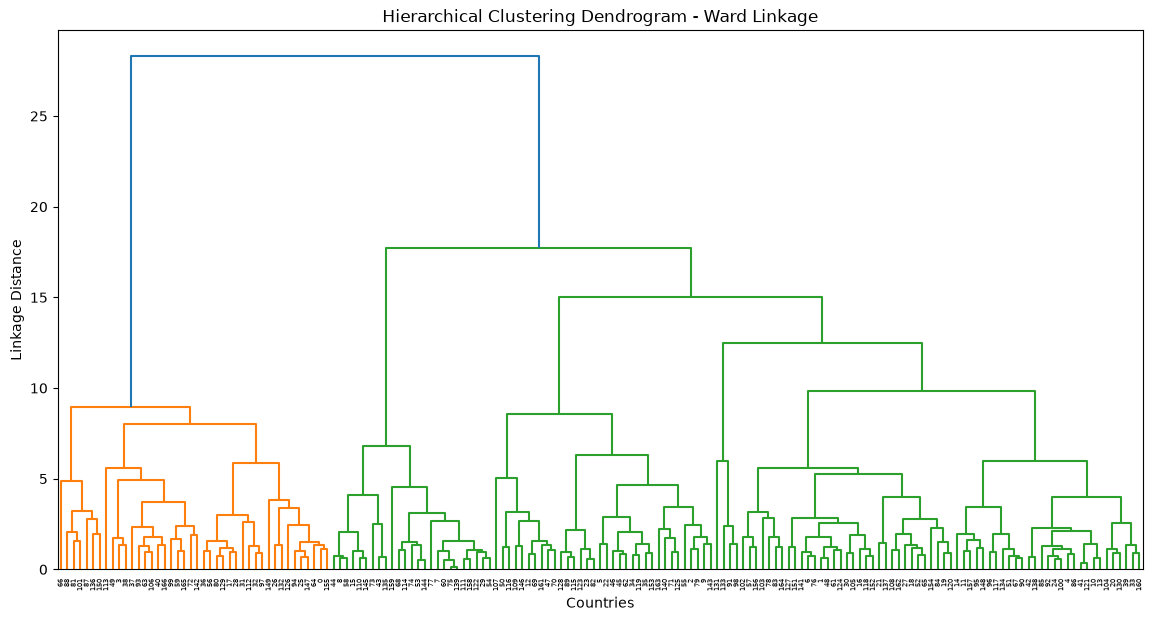

In [48]:
plt.figure(figsize=(14,7))
dendrogram(ward_linkage)
plt.title('Hierarchical Clustering Dendrogram - Ward Linkage')
plt.xlabel('Countries')
plt.ylabel('Linkage Distance')
plt.show()




### 8.2 Evaluating Ward Cluster Solutions

In [49]:
for n_cluster in [2,3]:

    hierarchical_model = AgglomerativeClustering(n_clusters=n_cluster, linkage= 'ward')

    labels= hierarchical_model.fit_predict(X_scaled_df)

    score = silhouette_score(X_scaled_df, labels)

    print(f"Clusters = {n_cluster}")
    print(f"Silhouette Score = {score:.3f}")
    print(pd.Series(labels).value_counts().sort_index())
    print()




Clusters = 2
Silhouette Score = 0.311
0    125
1     42
Name: count, dtype: int64

Clusters = 3
Silhouette Score = 0.215
0    100
1     42
2     25
Name: count, dtype: int64



In [50]:
hierarchical_2 = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

labels_h2 = hierarchical_2.fit_predict(X_scaled_df)

df_h2 = df.copy()
df_h2['cluster'] = labels_h2

df_h2.groupby('cluster')[clustering_features].median().round(2)

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,14.4,39.50,6.55,44.5,4.22,75.1,2.07,8200.0
1,90.4,23.65,5.79,42.8,7.22,59.8,5.20,763.5


In [51]:
hierarchical_3 = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels_h3 = hierarchical_3.fit_predict(X_scaled_df)

df_h3 = df.copy()
df_h3['cluster'] = labels_h3

df_h3.groupby('cluster')[clustering_features].median().round(2)

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,17.4,39.65,5.86,48.65,6.04,73.95,2.18,5935.0
1,90.4,23.65,5.79,42.80,7.22,59.80,5.20,763.5
2,4.2,38.70,9.64,37.10,0.87,80.70,1.86,44400.0


In [52]:
linkage_methods = ['single', 'complete', 'average', 'ward']

for method in linkage_methods:
    print(f"\nLinkage: {method}")

    for n_clusters in [2, 3]:

        model = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=method
        )

        labels = model.fit_predict(X_scaled_df)

        score = silhouette_score(X_scaled_df, labels)

        print(
            f"Clusters = {n_clusters} | "
            f"Silhouette Score = {score:.3f}"
        )


Linkage: single
Clusters = 2 | Silhouette Score = 0.388
Clusters = 3 | Silhouette Score = 0.333

Linkage: complete
Clusters = 2 | Silhouette Score = 0.406
Clusters = 3 | Silhouette Score = 0.256

Linkage: average
Clusters = 2 | Silhouette Score = 0.388
Clusters = 3 | Silhouette Score = 0.305

Linkage: ward
Clusters = 2 | Silhouette Score = 0.311
Clusters = 3 | Silhouette Score = 0.215


In [53]:
for method in linkage_methods:

    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels = model.fit_predict(X_scaled_df)

    print(f"\nLinkage: {method}")
    print(pd.Series(labels).value_counts().sort_index())


Linkage: single
0    166
1      1
Name: count, dtype: int64

Linkage: complete
0    162
1      5
Name: count, dtype: int64

Linkage: average
0    166
1      1
Name: count, dtype: int64

Linkage: ward
0    125
1     42
Name: count, dtype: int64


**Ward Cluster Selection:**

Ward linkage with **2 clusters** was selected as the most meaningful Hierarchical Clustering solution.

- The 2-cluster solution achieved a Silhouette Score of approximately **0.311**, compared with **0.215** for 3 clusters.
- The two clusters contained **125 and 42 countries**, respectively.
- The 42-country cluster showed substantially higher child mortality and fertility, along with lower life expectancy and GDPP, indicating a clearly more vulnerable group.
- Although some other linkage methods produced higher Silhouette Scores, they created highly imbalanced solutions in which only one or a few countries formed a separate cluster.
- Ward linkage therefore provided a more interpretable and actionable segmentation for the aid-prioritization objective.

The 2-cluster Ward solution is retained as a supporting model for identifying a core vulnerable group of countries.

## 9. DBSCAN Clustering

DBSCAN is evaluated to identify density-based country groupings and detect countries with unusual profiles that may not naturally belong to a dense cluster.

The same standardized feature matrix used for K-Means and Hierarchical Clustering is used so that distance calculations are comparable across features.

In [54]:
min_samples = 2 * X_scaled_df.shape[1]

print("Number of features:", X_scaled_df.shape[1])
print("Initial min_samples:", min_samples)

Number of features: 8
Initial min_samples: 16


### 9.1 DBSCAN Parameter Selection

An initial `min_samples` value of 16 was selected using the `2 × number of features` heuristic. A k-distance plot is used to identify a reasonable starting value for `eps`.

In [55]:
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled_df)

distances,indices = neighbors.kneighbors(X_scaled_df)

k_distances = np.sort(distances[:,-1])

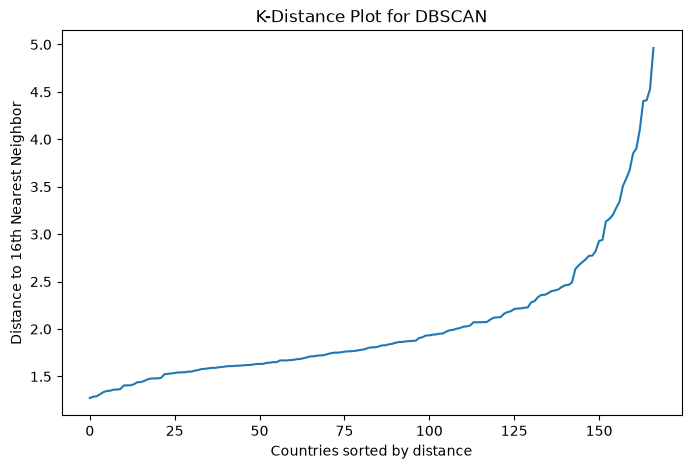

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(k_distances)

plt.xlabel('Countries sorted by distance')
plt.ylabel('Distance to 16th Nearest Neighbor')
plt.title('K-Distance Plot for DBSCAN')

plt.show()

In [57]:
dbscan_model = DBSCAN(eps=2.7, min_samples =16)

dbscan_labels = dbscan_model.fit_predict(X_scaled_df)
pd.Series(dbscan_labels).value_counts().sort_index()

-1      7
 0    160
Name: count, dtype: int64

In [58]:
df_dbscan = df.copy()
df_dbscan['dbscan_cluster'] = dbscan_labels

df_dbscan[
    df_dbscan['dbscan_cluster'] == -1
][['country'] + clustering_features]

,country,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
66,Haiti,208.0,15.300,6.91,64.7000,5.450,32.1,3.33,662
91,Luxembourg,2.8,175.000,7.77,142.0000,3.620,81.3,1.63,105000
98,Malta,6.8,153.000,8.65,154.0000,3.830,80.3,1.36,21100
107,Myanmar,64.4,0.109,1.97,0.0659,7.040,66.8,2.41,988
113,Nigeria,130.0,25.300,5.07,17.4000,104.000,60.5,5.84,2330
131,Seychelles,14.4,93.800,3.40,108.0000,-4.210,73.4,2.17,10800
133,Singapore,2.8,200.000,3.96,174.0000,-0.046,82.7,1.15,46600


In [59]:
for eps in [2.0, 2.2, 2.4, 2.6]:

    model = DBSCAN(
        eps=eps,
        min_samples=16
    )

    labels = model.fit_predict(X_scaled_df)

    print(f"\neps = {eps}")
    print(pd.Series(labels).value_counts().sort_index())


eps = 2.0
-1     18
 0    149
Name: count, dtype: int64

eps = 2.2
-1     15
 0    152
Name: count, dtype: int64

eps = 2.4
-1     10
 0    157
Name: count, dtype: int64

eps = 2.6
-1      7
 0    160
Name: count, dtype: int64


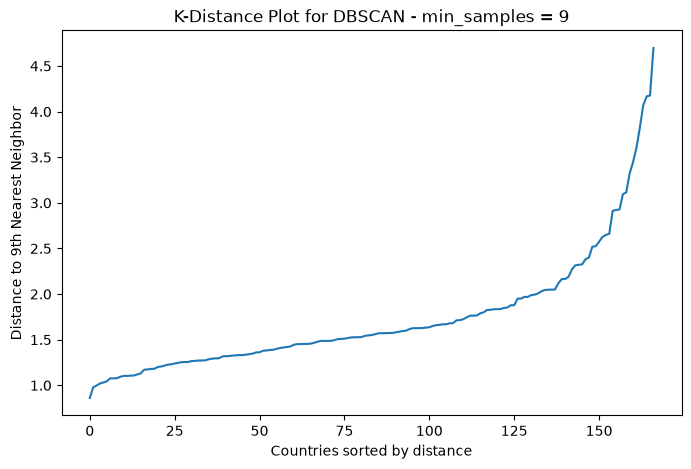

In [60]:
min_samples = 9

neighbors_9 = NearestNeighbors(n_neighbors=min_samples)
neighbors_9.fit(X_scaled_df)

distances_9, indices_9 = neighbors_9.kneighbors(X_scaled_df)

k_distances_9 = np.sort(distances_9[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances_9)

plt.xlabel('Countries sorted by distance')
plt.ylabel('Distance to 9th Nearest Neighbor')
plt.title('K-Distance Plot for DBSCAN - min_samples = 9')

plt.show()

### 9.2 Parameter Sensitivity

DBSCAN is sensitive to the choice of `eps` and `min_samples`. Therefore, multiple reasonable parameter combinations were evaluated rather than selecting a configuration from a single trial.

In [61]:
for eps in [1.4, 1.6, 1.8, 2.0]:

    model = DBSCAN(
        eps=eps,
        min_samples=9
    )

    labels = model.fit_predict(X_scaled_df)

    print(f"\neps = {eps}")
    print(pd.Series(labels).value_counts().sort_index())


eps = 1.4
-1    56
 0    90
 1    21
Name: count, dtype: int64

eps = 1.6
-1     32
 0    135
Name: count, dtype: int64

eps = 1.8
-1     22
 0    145
Name: count, dtype: int64

eps = 2.0
-1     16
 0    151
Name: count, dtype: int64


### 9.2 Parameter Sensitivity

DBSCAN is sensitive to the choice of `eps` and `min_samples`. Therefore, multiple reasonable parameter combinations were evaluated rather than selecting a configuration from a single trial.

## 10. Principal Component Analysis (PCA)

PCA is applied to the standardized clustering features to reduce dimensionality and visualize the existing cluster structure in two dimensions.

The clustering models were trained using all eight standardized features. PCA is used here primarily for visualization and interpretation rather than as a replacement for the original clustering input.

In [62]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled_df)

In [63]:
X_pca.shape

(167, 8)

In [64]:
pca.explained_variance_ratio_

array([0.50498058, 0.1879435 , 0.14005286, 0.08000733, 0.04073867,
       0.02654276, 0.01215622, 0.00757809])

**Observation:**  
PC1 explains approximately **50.5%** of the variance and PC2 explains **18.8%**. Together, the first two principal components explain about **69.3%** of the total variance, which is sufficient for a useful 2-D visualization while still leaving some information in the remaining components.

In [65]:
pca_df = pd.DataFrame(
    X_pca[:, :2],
    columns=['PC1', 'PC2'],
    index=X_scaled_df.index
)

pca_df['country'] = df['country']
pca_df['kmeans_cluster'] = df_final['cluster']

pca_df.head()

,PC1,PC2,country,kmeans_cluster
0,3.273869,-0.022062,Afghanistan,1
1,-0.646326,-0.332908,Albania,0
2,0.347011,-0.478988,Algeria,0
3,2.659635,1.345280,Angola,1
4,-1.446909,0.392582,Antigua and Barbuda,2


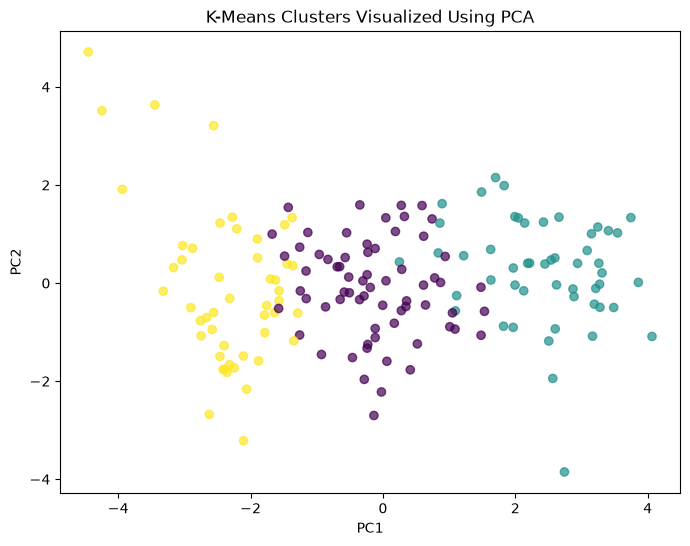

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['kmeans_cluster'],
    alpha=0.7
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clusters Visualized Using PCA')
plt.show()

In [67]:
pca_loadings = pd.DataFrame(
    pca.components_[:2],
    columns=clustering_features,
    index=['PC1', 'PC2']
)

pca_loadings.round(3)

,child_mort,exports,health,imports,inflation,life_expec,total_fer,gdpp
PC1,0.477,-0.278,-0.173,-0.152,0.266,-0.435,0.429,-0.446
PC2,0.132,0.582,-0.192,0.716,-0.125,-0.212,0.129,-0.132


**Principal Component Interpretation**

- **PC1** is primarily influenced by child mortality, total fertility, life expectancy, and GDPP. Higher PC1 values are associated with higher child mortality and fertility together with lower life expectancy and GDPP. Therefore, PC1 can broadly be interpreted as a **development/vulnerability dimension**.
- **PC2** is dominated by imports and exports and can broadly be interpreted as a **trade/external economic-structure dimension**.

The PCA visualization therefore provides an interpretable two-dimensional view of the country clusters while retaining approximately **69.3% of the total variance**.

## 11. Model Comparison and Final Approach Selection

K-Means, Agglomerative Hierarchical Clustering, and DBSCAN were evaluated using quantitative performance, cluster structure, business interpretability, and usefulness for aid prioritization.

In [68]:
model_comparison = pd.DataFrame({
    'Model': [
        'K-Means',
        'Hierarchical - Ward',
        'DBSCAN'
    ],
    'Selected Configuration': [
        'K = 3',
        '2 clusters',
        'Multiple eps/min_samples tested'
    ],
    'Silhouette Score': [
        0.239,
        0.311,
        np.nan
    ],
    'Cluster Structure': [
        '67 / 51 / 49',
        '125 / 42',
        'Mostly one dominant cluster + noise'
    ],
    'Business Interpretation': [
        'High / Intermediate / Lower vulnerability',
        'Vulnerable / Lower-vulnerability split',
        'Noise represents unusual profiles, not specifically vulnerability'
    ]
})

model_comparison

,Model,Selected Configuration,Silhouette Score,Cluster Structure,Business Interpretation
0,K-Means,K = 3,0.239,67 / 51 / 49,High / Intermediate / Lower vulnerability
1,Hierarchical - Ward,2 clusters,0.311,125 / 42,Vulnerable / Lower-vulnerability split
2,DBSCAN,Multiple eps/min_samples tested,NaN,Mostly one dominant cluster + noise,"Noise represents unusual profiles, not specifi..."


### 11.1 Cross-Model Agreement on Vulnerable Countries

To assess the consistency of the two interpretable clustering solutions, the vulnerable-country groups identified by K-Means and Ward Hierarchical Clustering were compared.

K-Means identified **51 countries** in its high-vulnerability cluster, while Ward Hierarchical Clustering identified **42 countries** in its vulnerable cluster.

In [69]:
kmeans_vulnerable = set(
    df_final.loc[df_final['cluster'] == 1, 'country']
)

ward_vulnerable = set(
    df_h2.loc[df_h2['cluster'] == 1, 'country']
)

print("K-Means vulnerable countries:", len(kmeans_vulnerable))
print("Ward vulnerable countries:", len(ward_vulnerable))

common_countries = kmeans_vulnerable & ward_vulnerable

print("Common vulnerable countries:", len(common_countries))

K-Means vulnerable countries: 51
Ward vulnerable countries: 42
Common vulnerable countries: 42


In [70]:
kmeans_only = kmeans_vulnerable - ward_vulnerable

df_final[
    df_final['country'].isin(kmeans_only)
][['country', 'child_mort', 'life_expec',
   'total_fer', 'gdpp', 'inflation']]

,country,child_mort,life_expec,total_fer,gdpp,inflation
21,Botswana,52.5,57.1,2.88,6350,8.92
50,Eritrea,55.2,61.7,4.61,482,11.60
84,Lao,78.9,63.8,3.15,1140,9.20
107,Myanmar,64.4,66.8,2.41,988,7.04
108,Namibia,56.0,58.6,3.60,5190,3.56
109,Nepal,47.0,68.3,2.61,592,15.10
116,Pakistan,92.1,65.3,3.85,1040,10.90
137,South Africa,53.7,54.3,2.59,7280,6.35
146,Tajikistan,52.4,69.6,3.51,738,12.50


**Interpretation:**

All **42 countries** identified as vulnerable by Ward Hierarchical Clustering are also contained within the **51-country high-vulnerability K-Means cluster**.

This complete overlap provides strong supporting evidence for a core group of vulnerable countries identified consistently across two different clustering approaches.

The remaining **9 countries** are classified as high-vulnerability by K-Means but not by Ward. These countries can be viewed as relatively less clear-cut members of the vulnerable segment compared with the 42-country consensus group.

### 11.2 Final Model Selection

Although Ward Hierarchical Clustering achieved a higher Silhouette Score (0.311) than the selected K-Means solution (0.239), K-Means with **K = 3** produced a more actionable segmentation for the business objective.

The K-Means solution separates countries into **high, intermediate, and lower vulnerability groups**, allowing HELP International to distinguish different levels of development need rather than relying on a broad two-group split.

Ward Hierarchical Clustering was retained as a supporting validation approach. Importantly, all **42 countries** identified as vulnerable by Ward were also included within the **51-country high-vulnerability K-Means cluster**, indicating substantial agreement on a core group of vulnerable countries.

DBSCAN generally produced one dominant dense cluster with varying numbers of noise points. Its noise observations represented unusual profiles at both vulnerable and highly developed extremes, making it less suitable for direct aid-priority segmentation.

Therefore, **K-Means with K = 3 is selected as the primary clustering approach**, with Hierarchical Clustering providing supporting evidence for the vulnerable-country segment.

In [71]:
core_vulnerable = df_final[
    df_final['country'].isin(common_countries)
].copy()

## 12. Country Prioritization

The clustering stage identifies groups of countries with similar development profiles but does not directly determine how HELP International should allocate its limited aid budget.

Countries consistently identified as vulnerable by both K-Means and Hierarchical Clustering are therefore evaluated further using key humanitarian and development indicators.

In [72]:
priority_df = core_vulnerable[
    ['country', 'child_mort', 'life_expec', 'total_fer', 'gdpp']
].copy()

priority_df['child_mort_score'] = (
    priority_df['child_mort'] - priority_df['child_mort'].mean()
) / priority_df['child_mort'].std(ddof=0)

priority_df['total_fer_score'] = (
    priority_df['total_fer'] - priority_df['total_fer'].mean()
) / priority_df['total_fer'].std(ddof=0)

priority_df['life_expec_score'] = (
    priority_df['life_expec'].mean() - priority_df['life_expec']
) / priority_df['life_expec'].std(ddof=0)

priority_df['gdpp_score'] = (
    priority_df['gdpp'].mean() - priority_df['gdpp']
) / priority_df['gdpp'].std(ddof=0)

### Priority Score Weighting Strategy

The dataset does not provide stakeholder-defined importance weights for the selected vulnerability indicators. Therefore, the prioritization score is treated as a transparent decision-support framework rather than an objectively learned model output.

Two weighting approaches are evaluated:

- **Equal weighting:** each indicator contributes equally, providing a neutral baseline.
- **Humanitarian weighting:** greater emphasis is placed on child mortality, followed by life expectancy and GDPP, while total fertility is used as a supporting vulnerability indicator.

For the humanitarian scenario, the weights are:

- Child mortality: **40%**
- Life expectancy: **25%**
- GDPP: **25%**
- Total fertility: **10%**

These weights reflect a reasonable humanitarian prioritization assumption and should ideally be validated or adjusted with HELP International based on its program objectives and operational priorities.

In [73]:
priority_df['score_equal'] = priority_df[
    [
        'child_mort_score',
        'life_expec_score',
        'total_fer_score',
        'gdpp_score'
    ]
].mean(axis=1)

priority_df['score_humanitarian'] = (
    0.40 * priority_df['child_mort_score'] +
    0.25 * priority_df['life_expec_score'] +
    0.25 * priority_df['gdpp_score'] +
    0.10 * priority_df['total_fer_score']
)

In [74]:
top10_equal = priority_df.sort_values(
    'score_equal',
    ascending=False
).head(10)

top10_humanitarian = priority_df.sort_values(
    'score_humanitarian',
    ascending=False
).head(10)

In [75]:
top10_equal[
    ['country', 'child_mort', 'life_expec',
     'total_fer', 'gdpp', 'score_equal']
]

,country,child_mort,life_expec,total_fer,gdpp,score_equal
66,Haiti,208.0,32.1,3.33,662,1.388919
112,Niger,123.0,58.8,7.49,348,0.973093
32,Chad,150.0,56.5,6.59,897,0.947795
31,Central African Republic,149.0,47.5,5.21,446,0.934823
97,Mali,137.0,59.5,6.55,708,0.748312
132,Sierra Leone,160.0,55.0,5.20,399,0.732653
37,"Congo, Dem. Rep.",116.0,57.5,6.54,334,0.706056
25,Burkina Faso,116.0,57.9,5.87,575,0.479518
26,Burundi,93.6,57.7,6.26,231,0.469011
106,Mozambique,101.0,54.5,5.56,419,0.427851


In [76]:
top10_humanitarian[
    ['country', 'child_mort', 'life_expec',
     'total_fer', 'gdpp', 'score_humanitarian']
]

,country,child_mort,life_expec,total_fer,gdpp,score_humanitarian
66,Haiti,208.0,32.1,3.33,662,2.190738
31,Central African Republic,149.0,47.5,5.21,446,1.165592
132,Sierra Leone,160.0,55.0,5.20,399,1.012427
32,Chad,150.0,56.5,6.59,897,0.949987
112,Niger,123.0,58.8,7.49,348,0.707264
97,Mali,137.0,59.5,6.55,708,0.701333
37,"Congo, Dem. Rep.",116.0,57.5,6.54,334,0.570431
25,Burkina Faso,116.0,57.9,5.87,575,0.456957
64,Guinea-Bissau,114.0,55.6,5.05,547,0.431136
106,Mozambique,101.0,54.5,5.56,419,0.393080


In [77]:
set(top10_equal['country']) & set(top10_humanitarian['country'])

{'Burkina Faso',
 'Central African Republic',
 'Chad',
 'Congo, Dem. Rep.',
 'Haiti',
 'Mali',
 'Mozambique',
 'Niger',
 'Sierra Leone'}

### 12.1 Priority Ranking Sensitivity

Two prioritization approaches were evaluated:

1. **Equal weighting**, where child mortality, life expectancy, GDPP, and total fertility contribute equally.
2. **Humanitarian weighting**, which gives greater importance to child mortality while retaining the other development indicators.

The resulting rankings were highly consistent. **Nine of the Top 10 countries appeared under both approaches**, with Haiti ranked as the highest-priority country in both cases.

This stability suggests that the highest-priority recommendations are not strongly dependent on the exact weighting scheme. The humanitarian-weighted score is therefore used as the primary prioritization view, while the equal-weight ranking serves as a sensitivity check.

In [78]:
top5_priority = top10_humanitarian.head(5)

top5_priority[
    ['country', 'child_mort', 'life_expec',
     'total_fer', 'gdpp', 'score_humanitarian']
]

,country,child_mort,life_expec,total_fer,gdpp,score_humanitarian
66,Haiti,208.0,32.1,3.33,662,2.190738
31,Central African Republic,149.0,47.5,5.21,446,1.165592
132,Sierra Leone,160.0,55.0,5.20,399,1.012427
32,Chad,150.0,56.5,6.59,897,0.949987
112,Niger,123.0,58.8,7.49,348,0.707264


### 12.2 Final Aid Priority Recommendation

Based on the final vulnerability analysis, the following countries emerge as the highest-priority candidates for immediate assessment by HELP International:

1. **Haiti**
2. **Central African Republic**
3. **Sierra Leone**
4. **Chad**
5. **Niger**

These countries consistently exhibit severe vulnerability across multiple development indicators, including high child mortality, low life expectancy, low GDPP, and other socioeconomic pressures.

The shortlist was derived from countries identified as vulnerable by both K-Means and Hierarchical Clustering and was further prioritized using a humanitarian-weighted vulnerability score. The ranking was also tested using an equal-weight scoring approach, with nine of the Top 10 countries remaining common across both methods, indicating that the prioritization is reasonably robust to changes in indicator weighting.

HELP International should treat these five countries as the **highest-priority group for detailed needs assessment and program planning**.

### 12.3 Recommendation Limitations

The analysis identifies **which countries should receive priority attention**, but it does not determine the exact amount of funding that should be allocated to each country.

The available dataset does not include information such as population requiring assistance, intervention costs, existing aid programs, implementation capacity, or expected impact per dollar.

Therefore, the available **$10 million fund should not be divided mechanically across the shortlisted countries**. Final allocation should be determined after country-level needs assessment and program feasibility analysis.

The clustering and prioritization results should be used as a data-driven screening tool to guide HELP International toward the countries requiring the most immediate investigation.

In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))



Project root: /Users/avdhootkulkarni/Desktop/country-aid-clustering


In [81]:
from src.preprocessing import transform_features, MODEL_FEATURES

prod_transformed = transform_features(df)

same_values = np.allclose(
    prod_transformed[MODEL_FEATURES].to_numpy(),
    df_model[MODEL_FEATURES].to_numpy()
)

print("Production preprocessing matches notebook:", same_values)

Production preprocessing matches notebook: True


In [82]:
max_difference = np.max(
    np.abs(
        prod_transformed[MODEL_FEATURES].to_numpy()
        - df_model[MODEL_FEATURES].to_numpy()
    )
)

print("Maximum difference:", max_difference)

Maximum difference: 0.0
